# Parte 6: Perfis, aplicações e conclusão
**Responsável:** Rafael · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** traduzir os clusters do SOM (Parte 4) em **perfis de cliente com nome**, usando os gastos em valores
reais, testar as hipóteses de perfis do plano, discutir aplicações e fechar o projeto com conclusão e limitações.

## 1. Bibliotecas e dados

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from minisom import MiniSom

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (a mesma da Parte 1)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])
# Clusters: cores diferentes das do canal, para não confundir "cluster" com "Horeca/Varejo"
COR_CLUSTER = ["#1baf7a", "#6250d6", "#eda100"]          # aqua, violeta, amarelo
MARCA_CLUSTER = ["o", "s", "^"]
CINZAS = LinearSegmentedColormap.from_list("cinzas", ["#f4f4f2", "#52514e"])   # U-Matrix: escuro = distância maior

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)

GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_scaled = pd.read_csv("dados/X_scaled.csv").values
df = pd.read_csv("dados/dados_preprocessados.csv")
print("X_scaled:", X_scaled.shape, "| df:", df.shape)
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans

clusters = pd.read_csv("dados/clusters.csv")
base = df.join(clusters)
base["Total"] = base[GASTOS].sum(axis=1)
K = int(base["cluster"].max() + 1)
print("Clusters:", base["cluster"].value_counts().sort_index().to_dict(), "| outliers:", int(base["outlier"].sum()))

X_scaled: (440, 6) | df: (440, 16)
Clusters: {0: 203, 1: 93, 2: 144} | outliers: 22


## 2. Perfil de cada cluster em valores reais
Usamos a **mediana**, porque os gastos são muito assimétricos (Parte 1) e a média seria puxada por poucos clientes grandes.
A última linha é a mediana da base inteira, para servir de referência.

In [2]:
perfil = base.groupby("cluster")[GASTOS + ["Total"]].median().round(0).astype(int)
geral = base[GASTOS + ["Total"]].median().round(0).astype(int).rename("base inteira")
perfil.insert(0, "clientes", base["cluster"].value_counts().sort_index())
perfil["% Varejo"] = (base.groupby("cluster")["Canal"].apply(lambda s: (s == "Varejo").mean()) * 100).round(0).astype(int)
perfil["% do faturamento"] = (base.groupby("cluster")["Total"].sum() / base["Total"].sum() * 100).round(0).astype(int)
tabela_perfil = pd.concat([perfil, geral.to_frame().T.assign(clientes=len(base), **{
    "% Varejo": round((base["Canal"] == "Varejo").mean() * 100), "% do faturamento": 100})])
tabela_perfil

,clientes,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total,% Varejo,% do faturamento
0,203,9351,1492,2067,2046,246,684,17946,1,29
1,93,2362,6380,10518,425,4196,531,27863,68,20
2,144,12630,6726,9278,2506,2508,1860,45966,53,52
base inteira,440,8504,3627,4756,1526,816,966,27492,32,100


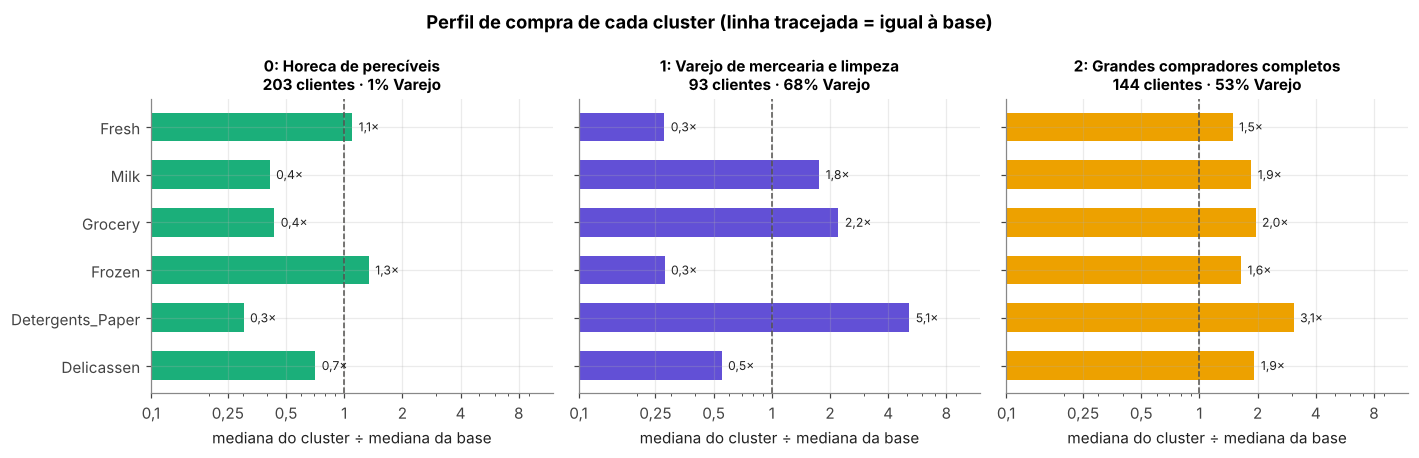

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,1.10,0.41,0.43,1.34,0.30,0.71
1,0.28,1.76,2.21,0.28,5.14,0.55
2,1.49,1.85,1.95,1.64,3.07,1.93


In [3]:
# Índice: mediana do cluster ÷ mediana da base. 1 = igual à base; 2 = o dobro; 0,5 = a metade.
indice = perfil[GASTOS].div(geral[GASTOS])
NOMES = {0: "Horeca de perecíveis", 1: "Varejo de mercearia e limpeza", 2: "Grandes compradores completos"}

fig, axes = plt.subplots(1, K, figsize=(13, 4.2), sharey=True)
for c, ax in enumerate(axes):
    v = indice.loc[c]
    ax.barh(GASTOS, v.values, color=COR_CLUSTER[c], height=0.6, left=0)
    ax.axvline(1, color=CINZA, lw=1, ls="--")
    for i, x in enumerate(v.values):
        ax.text(x * 1.08, i, f"{x:.1f}×".replace(".", ","), va="center", fontsize=8, color="#222")
    ax.set_xscale("log"); ax.set_xlim(0.1, 12)
    ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0,1", "0,25", "0,5", "1", "2", "4", "8"])
    ax.set_title(f"{c}: {NOMES[c]}\n{int(perfil.loc[c, 'clientes'])} clientes · {int(perfil.loc[c, '% Varejo'])}% Varejo",
                 fontsize=10)
    ax.set_xlabel("mediana do cluster ÷ mediana da base")
axes[0].invert_yaxis()
fig.suptitle("Perfil de compra de cada cluster (linha tracejada = igual à base)", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/06_perfis_clusters.png", bbox_inches="tight"); plt.show()
indice.round(2)

**Leitura (índice = mediana do cluster ÷ mediana da base):**
- **Cluster 0 (203 clientes, 46% da base, 29% do faturamento):**
  - compra `Fresh` (1,1×) e `Frozen` (1,3×) na média ou pouco acima;
  - compra **pouquíssima mercearia e limpeza**: `Detergents_Paper` 0,3×, `Milk` e `Grocery` 0,4×;
  - o gasto total mediano (17.946) é 35% menor que o da base;
  - é o padrão de restaurantes e hotéis: compram comida, não produtos de prateleira.
- **Cluster 1 (93 clientes, 21%, 20% do faturamento):**
  - é o espelho do cluster 0: `Detergents_Paper` 5,1×, `Grocery` 2,2× e `Milk` 1,8×;
  - `Fresh` e `Frozen` ficam em **0,3×**;
  - o total mediano (27.863) é igual ao da base;
  - é o padrão de loja de secos e limpeza, que praticamente não trabalha com perecíveis.
- **Cluster 2 (144 clientes, 33%, 52% do faturamento):**
  - fica **acima da base em todas as categorias** (de 1,5× a 3,1×);
  - o total mediano (45.966) é 1,7× o da base;
  - **um terço dos clientes responde por metade do faturamento.**

**Hipóteses do plano:**
- "Restaurantes e hotéis" (alto Fresh/Frozen): **confirmada** (cluster 0).
- "Mercados e varejo" (alto Grocery/Detergents_Paper): **confirmada**, com um ajuste (cluster 1). Trata-se de um varejo
  **sem perecíveis**.
- "Pequenos compradores": **não aparece com k = 3** (ver a seção 4).
- **Não estava prevista:** um grupo de **grandes compradores completos**, o mais importante para o faturamento.

## 3. Canal e região de cada cluster

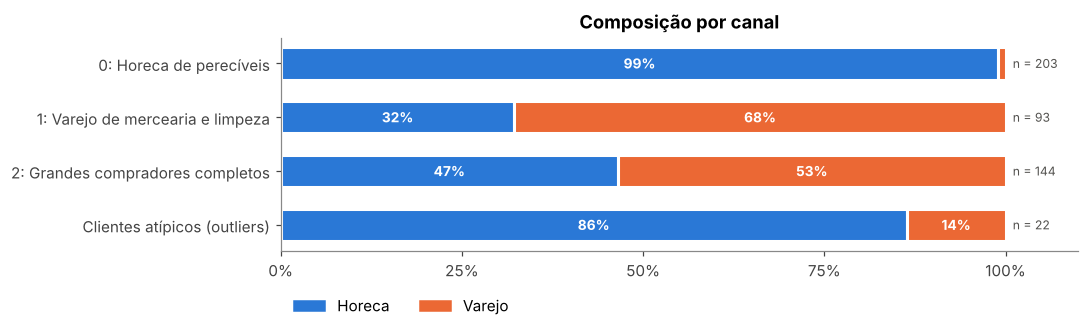

Regiao,Lisboa,Outras,Porto
cluster,,,
0,0.17,0.71,0.12
1,0.18,0.70,0.12
2,0.17,0.74,0.08


Teste qui-quadrado cluster × região: p = 0.85


In [4]:
grupos = [(f"{c}: {NOMES[c]}", base["cluster"] == c) for c in range(K)] + [("Clientes atípicos (outliers)", base["outlier"])]
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, (rot, m) in enumerate(grupos):
    p_h = (base.loc[m, "Canal"] == "Horeca").mean()
    ax.barh(i, p_h, color=AZUL, height=0.6, edgecolor="white", linewidth=2)
    ax.barh(i, 1 - p_h, left=p_h, color=LARANJA, height=0.6, edgecolor="white", linewidth=2)
    if p_h > 0.08: ax.text(p_h / 2, i, f"{p_h:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    if 1 - p_h > 0.08: ax.text(p_h + (1 - p_h) / 2, i, f"{1 - p_h:.0%}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(1.01, i, f"n = {int(m.sum())}", va="center", fontsize=8, color=CINZA)
ax.set_yticks(range(len(grupos))); ax.set_yticklabels([g[0] for g in grupos]); ax.invert_yaxis()
ax.set_xlim(0, 1.1); ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.grid(False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Horeca"), Patch(color=LARANJA, label="Varejo")], ncol=2, frameon=False,
          loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("Composição por canal")
plt.tight_layout(); plt.savefig("figuras/06_canal_por_cluster.png", bbox_inches="tight"); plt.show()

reg = pd.crosstab(base["cluster"], base["Regiao"], normalize="index").round(2)
display(reg)
chi2, p, _, _ = chi2_contingency(pd.crosstab(base["cluster"], base["Regiao"]))
print(f"Teste qui-quadrado cluster × região: p = {p:.2f}")

**Leitura:**
- **Cluster 0 é praticamente só Horeca (99%).**
- **Cluster 1 é majoritariamente Varejo (68%)**, mas um terço é Horeca com padrão de compra de loja. O perfil de compra não segue
  o canal cadastrado à risca.
- **Cluster 2 é meio a meio (47% Horeca, 53% Varejo).** Aqui está o valor do SOM: segmentar só pelo `Channel` esconderia que existe
  um grupo de clientes grandes que compram de tudo, vindos dos dois canais e somando 52% do faturamento.
- **Os atípicos são quase todos Horeca (86%).**
- **A região não diferencia os grupos:** em todos os clusters, cerca de 70% são de "Outras", 17% de Lisboa e de 8% a 12% do Porto.
  O teste qui-quadrado não encontra relação entre cluster e região (p = 0,85). **O perfil de compra não depende de onde o cliente está.**

## 4. Testando as hipóteses de perfis do plano
O PROJETO.md listava quatro perfis a confirmar: "Restaurantes e hotéis", "Mercados e varejo", "Pequenos compradores" e "Clientes atípicos".
Com k = 3, aparecem dois dos quatro previstos e um que não estava previsto ("grandes compradores mistos"). Os "pequenos compradores"
não formam um cluster próprio. Para testar se eles existem, olhamos o que acontece com **k = 4** no mesmo mapa.

In [5]:
# Mapa treinado na Parte 2 (Roger)
try:
    with open("dados/som.pkl", "rb") as f:
        som = pickle.load(f)
except Exception as erro_pickle:
    # Plano B: se o pickle não abrir (versão diferente de numpy/minisom), recria o mapa a partir dos pesos salvos
    print("som.pkl não abriu, recriando a partir de dados/som_pesos.npy:", erro_pickle)
    som = MiniSom(10, 10, X_scaled.shape[1], sigma=2.0, learning_rate=0.3, random_seed=SEED)
    som._weights = np.load("dados/som_pesos.npy")

LADO = som.get_weights().shape[0]
bmu = np.array([som.winner(x) for x in X_scaled])          # neurônio vencedor (BMU) de cada cliente
print("Mapa:", som.get_weights().shape, "| QE:", round(som.quantization_error(X_scaled), 4),
      "| TE:", round(som.topographic_error(X_scaled), 4))
pesos = som.get_weights().reshape(-1, X_scaled.shape[1])
idx_bmu = bmu[:, 0] * LADO + bmu[:, 1]
c4 = KMeans(n_clusters=4, random_state=SEED, n_init=10).fit(pesos).labels_[idx_bmu]
print("Como os clusters de k = 3 se dividem em k = 4:")
display(pd.crosstab(pd.Series(base["cluster"].values, name="k = 3"), pd.Series(c4, name="k = 4")))
p4 = base.assign(c4=c4).groupby("c4")[GASTOS + ["Total"]].median().round(0).astype(int)
p4.insert(0, "clientes", pd.Series(c4).value_counts().sort_index())
p4["% Varejo"] = (base.assign(c4=c4).groupby("c4")["Canal"].apply(lambda s: (s == "Varejo").mean()) * 100).round(0).astype(int)
p4

Mapa: (10, 10, 6) | QE: 0.8977 | TE: 0.05
Como os clusters de k = 3 se dividem em k = 4:


k = 4,0,1,2,3
k = 3,,,,
0,144,0,59,0
1,4,4,0,85
2,33,111,0,0


,clientes,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total,% Varejo
c4,,,,,,,,,
0,181,10766,2160,2501,2532,356,933,22422,3
1,115,12119,7961,11593,1920,3881,2098,46962,66
2,59,7005,803,1296,1092,146,360,12412,0
3,85,2137,6570,10704,480,4424,501,27938,72


**Leitura:**
- Com k = 4, o cluster 0 (Horeca de perecíveis) se divide em dois:
  - 144 clientes vão para um Horeca "normal" (total mediano de 22.422);
  - **59 clientes formam um grupo de pequenos compradores**: 0% Varejo, total mediano de 12.412 (menos da metade da base) e gasto
    abaixo da base em **todas** as categorias.
- A hipótese "pequenos compradores" existe, mas como um **subgrupo do Horeca**, e não como um perfil independente.
- O silhouette cai de 0,304 (k = 3) para 0,253 (k = 4), então essa divisão é mais fraca que as outras.
- **Recomendação:** apresentar k = 3 como resultado principal e citar os pequenos compradores como subsegmento do Horeca, útil se
  o negócio quiser uma política específica (pedido mínimo, frete) para eles.

## 5. Os clientes atípicos

In [6]:
atip = base[base["outlier"]]
print(f"{len(atip)} clientes atípicos | {(atip['Canal'] == 'Horeca').mean():.0%} Horeca | "
      f"{atip['Total'].sum() / base['Total'].sum():.1%} do faturamento")
print("Com algum gasto ≤ 50 numa categoria:", int((atip[GASTOS].min(axis=1) <= 50).sum()))
print("Total anual: mediana", int(atip["Total"].median()), "contra", int(base["Total"].median()), "na base")

22 clientes atípicos | 86% Horeca | 5.7% do faturamento
Com algum gasto ≤ 50 numa categoria: 17
Total anual: mediana 29507 contra 27492 na base


**Leitura:**
- Os 22 atípicos **não são clientes pequenos**: o total anual mediano deles (29.507) fica até um pouco acima do da base (27.492).
- Juntos, somam 5,7% do faturamento.
- 17 dos 22 têm uma categoria **inteira** com gasto ≤ 50 por ano, enquanto gastam normalmente nas outras.
- Há duas leituras possíveis, e as duas são acionáveis:
  1. **Erro de cadastro**: um gasto de 3 unidades monetárias num ano é suspeito e vale conferir;
  2. **O cliente compra aquela categoria em outro fornecedor**: é uma **oportunidade concreta de venda cruzada**, porque se sabe
     exatamente o que oferecer.
- "Clientes atípicos" funciona como uma **marcação** que atravessa os três perfis (13 estão no cluster 0, 7 no 1 e 2 no 2).

## 6. Perfis nomeados

| Perfil | Clientes | % do faturamento | Assinatura (vs. mediana da base) | Canal |
|---|---|---|---|---|
| **0. Horeca de perecíveis** (restaurantes e hotéis) | 203 (46%) | 29% | Fresh 1,1×, Frozen 1,3×; mercearia/limpeza 0,3-0,4×; total 0,65× | 99% Horeca |
| **1. Varejo de mercearia e limpeza** (lojas de secos) | 93 (21%) | 20% | Detergents_Paper 5,1×, Grocery 2,2×; Fresh e Frozen 0,3× | 68% Varejo |
| **2. Grandes compradores completos** | 144 (33%) | **52%** | tudo acima da base (1,5-3,1×); total 1,7× | 53% Varejo / 47% Horeca |
| **Clientes atípicos** (marcação, não cluster) | 22 (5%) | 6% | uma categoria com gasto quase zero (17 de 22) ou gasto extremo | 86% Horeca |

Subsegmento opcional (k = 4): **pequenos compradores Horeca**, com 59 clientes, gasto abaixo da base em tudo e total 0,45×.

## 7. Aplicação prática: classificar um cliente novo
Para usar o mapa com um cliente que não estava na base, é preciso aplicar **o mesmo pré-processamento** (log1p + o mesmo
`StandardScaler`). A Parte 1 não salvou o scaler. Como o `StandardScaler` é determinístico, recriamos o scaler com os mesmos dados,
conferimos que ele reproduz o `X_scaled` e salvamos em `dados/scaler.pkl`.

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(np.log1p(df[GASTOS]))
print("Reproduz o X_scaled da Parte 1?", np.allclose(scaler.transform(np.log1p(df[GASTOS])), X_scaled))
with open("dados/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

LIMITE_OUTLIER = np.percentile(base["erro_quant"], 95)
cluster_neuronio = np.full((LADO, LADO), -1)
for (x, y), c in zip(bmu, base["cluster"]):
    cluster_neuronio[x, y] = c
assert (cluster_neuronio >= 0).all(), "algum neurônio ficou sem cluster"

def classificar(gastos: dict) -> dict:
    """Recebe os 6 gastos anuais de um cliente e devolve neurônio, perfil e se é atípico."""
    z = scaler.transform(np.log1p(pd.DataFrame([gastos])[GASTOS]))[0]
    x, y = som.winner(z)
    erro = np.linalg.norm(z - som.get_weights()[x, y])
    c = int(cluster_neuronio[x, y])
    return {"bmu": (int(x), int(y)), "cluster": c, "perfil": NOMES[c], "erro": round(float(erro), 2),
            "atipico": bool(erro > LIMITE_OUTLIER)}

exemplos = {
    "restaurante":       dict(Fresh=15000, Milk=2000, Grocery=2500, Frozen=3000, Detergents_Paper=300, Delicassen=1000),
    "minimercado":       dict(Fresh=1000, Milk=8000, Grocery=15000, Frozen=300, Detergents_Paper=6000, Delicassen=500),
    "hotel grande":      dict(Fresh=25000, Milk=12000, Grocery=15000, Frozen=5000, Detergents_Paper=4000, Delicassen=4000),
    "sem Grocery (erro?)": dict(Fresh=12000, Milk=3000, Grocery=5, Frozen=2000, Detergents_Paper=500, Delicassen=900),
}
pd.DataFrame({k: classificar(v) for k, v in exemplos.items()}).T

Reproduz o X_scaled da Parte 1? True


,bmu,cluster,perfil,erro,atipico
restaurante,"(1, 6)",0,Horeca de perecíveis,0.37,False
minimercado,"(8, 2)",1,Varejo de mercearia e limpeza,0.87,False
hotel grande,"(8, 9)",2,Grandes compradores completos,0.67,False
sem Grocery (erro?),"(0, 2)",0,Horeca de perecíveis,4.49,True


**Leitura:**
- O scaler recriado reproduz exatamente o `X_scaled` da Parte 1. Ele foi salvo em `dados/scaler.pkl`, e a partir de agora qualquer
  cliente novo pode ser classificado.
- Os quatro exemplos inventados caem onde se espera:
  - o **restaurante** vai para o Horeca de perecíveis (erro 0,37, bem ajustado);
  - o **minimercado** vai para o Varejo de mercearia e limpeza;
  - o **hotel grande** vai para os Grandes compradores completos;
  - o cliente com **Grocery = 5** é marcado como **atípico** (erro 4,49, acima do limite de 1,87). É o tipo de cadastro que deveria ser conferido.

## 8. Aplicações

| Aplicação | Como usar os perfis |
|---|---|
| **Gestão de contas** | Os **Grandes compradores completos** são 33% dos clientes e 52% do faturamento: prioridade para atendimento dedicado, retenção e negociação de volume. |
| **Venda cruzada (marketing direcionado)** | O **Horeca de perecíveis** compra só 0,3× da mediana em `Detergents_Paper`, mas restaurante usa produto de limpeza. Provavelmente compra em outro lugar, então vale um kit de limpeza/descartáveis para esse grupo. Para o **Varejo de mercearia**, ofertas de volume em secos e limpeza; empurrar perecíveis tende a não funcionar (0,3×). |
| **Logística e estoque** | O Horeca de perecíveis depende de **cadeia de frio** (Fresh/Frozen) e entregas frequentes. O Varejo de mercearia compra produtos secos, que permitem entregas maiores e menos frequentes. A região não muda o perfil (p = 0,85), então o mix de estoque por região pode ser o mesmo. |
| **Qualidade de dados e anomalias** | Os 22 atípicos são uma lista curta para conferir: gasto de 3 unidades num ano em uma categoria é erro de cadastro ou um cliente que compra aquilo em outro fornecedor. |
| **Classificação de clientes novos** | Com `som.pkl` + `scaler.pkl`, um cliente novo recebe neurônio, perfil e alerta de atípico em uma linha de código (seção 7). |

## 9. Conclusão
O SOM cumpriu o que o enunciado pedia:
- **mapa treinado** com critério explícito (10×10, σ = 2,0, lr = 0,3; QE = 0,898, TE = 0,050);
- **U-Matrix** e component planes interpretados;
- **três clusters com nome**;
- **22 clientes atípicos** identificados e explicados;
- **comparação com K-Means e PCA**.

**Os achados principais:**
1. **Dois eixos de compra:** mercearia/limpeza (`Milk`, `Grocery`, `Detergents_Paper`) e perecíveis (`Fresh`, `Frozen`, `Delicassen`).
   O SOM, o PCA (71% da variância em 2 componentes) e a EDA mostram os mesmos dois eixos.
2. **Três perfis:**
   - Horeca de perecíveis;
   - Varejo de mercearia e limpeza;
   - Grandes compradores completos (1/3 dos clientes, 1/2 do faturamento, com os dois canais misturados).
3. **O mapa separa os canais (92% de pureza por neurônio) sem ter visto o canal**, e mostra o que o canal esconde: o grupo misto de grandes compradores.
4. **Comparação:** o K-Means direto concorda com o SOM em 88% dos clientes, é um pouco mais compacto (silhouette 0,26 contra 0,22) e bem mais
   estável. A vantagem do SOM está na **interpretação**: mapa, fronteiras, explicação por variável e outliers num só modelo.

## 10. Limitações
1. **Base pequena e específica:** 440 clientes de um único distribuidor em Portugal, só com o gasto anual por categoria. Não há margem,
   frequência de pedidos nem série no tempo.
2. **Os grupos não são bem separados.** O silhouette fica ≤ 0,33 em qualquer k: os perfis são **cortes num contínuo**. A escolha de k = 3
   (cotovelo) tem parte de julgamento. O silhouette preferia k = 2 por pouco, e k = 4 separa os pequenos compradores.
3. **Sensibilidade a hiperparâmetros e à semente:**
   - QE e TE brigam entre si, então a configuração depende do critério adotado (Parte 2);
   - trocar a semente muda a fronteira dos clusters (ARI médio de 0,71). Os perfis se mantêm, mas um cliente de fronteira pode trocar de grupo.
4. **O pré-processamento define quem é outlier.** O `log1p` estica os gastos quase nulos: 3 unidades ficam muito longe de 3.000. Por isso
   a maioria dos atípicos é "gasto quase zero numa categoria". Sem o log, os outliers seriam os clientes gigantes. Os dois são válidos,
   mas medem coisas diferentes.
5. **A validação externa é limitada:** só temos o `Channel` (que concorda com o mapa) e a `Region` (que não diferencia nada). Não há um
   rótulo de verdade para os perfis.

**Próximos passos:**
- validar os perfis com a área comercial;
- conferir os 22 atípicos;
- se houver dados de pedidos, repetir a análise com frequência e margem.